# MDPToolbox vs Marmote vs MDPSolver

Les 51 modèles du catalogue, avec leurs paramètres par défaut, et les 17 solveurs
de ces trois bibliothèques sont ajoutés explicitement, un par un.

Utiliser un noyau Python 3.11+ avec les dépendances installées depuis la racine :
```sh
python -m pip install -e ".[notebooks,mdptoolbox,marmote,mdpsolver,maze]"
```

Le benchmark vérifie la précision absolue par le résidu complet de Bellman.
Le timeout s'applique à chaque essai de solveur ; les modèles réutilisent leur
cache lorsqu'il existe. Utiliser MDPSolver 0.10.2 ou plus récent pour le correctif
VI/SOR ; les exports historiques en 0.10.1 peuvent contenir les anciennes erreurs.

In [4]:
# Garder les caches et les exports dans artifacts/ à la racine du dépôt.
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)

In [5]:
import random

import matplotlib.pyplot as plt
import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.99
SIZE = "small"
PRECISION = 1e-3
REPEATS = 3
SEED = 0
TIMEOUT = 5  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

In [ ]:
bench = Benchmark(default_solvers=False)

bench.reset()
bench.add_solver(family=["vi"], backend=["mdpsolver", "marmote", "mdptoolbox"])
bench.add_mdp(category="abstract", size="medium")
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=TIMEOUT,
    verbose=True,
)

fig, ax = plt.subplots(figsize=(24, 9))
bench.plot_heat(reference="marmote_vi", ax=ax, show=False)
plt.show()

400_10_block_0.85_10 / marmote_vi [1/3]: success (0.381 s)
400_10_block_0.85_10 / marmote_vi [2/3]: success (0.378 s)
400_10_block_0.85_10 / marmote_vi [3/3]: success (0.378 s)
400_10_block_0.85_10 / marmote_vigs [1/3]: success (0.261 s)
400_10_block_0.85_10 / marmote_vigs [2/3]: success (0.259 s)
400_10_block_0.85_10 / marmote_vigs [3/3]: success (0.257 s)
400_10_block_0.85_10 / mdpsolver_vi [1/3]: success (0.207 s)
400_10_block_0.85_10 / mdpsolver_vi [2/3]: success (0.197 s)
400_10_block_0.85_10 / mdpsolver_vi [3/3]: success (0.201 s)
400_10_block_0.85_10 / mdpsolver_vigs [1/3]: success (0.580 s)
400_10_block_0.85_10 / mdpsolver_vigs [2/3]: success (0.575 s)
400_10_block_0.85_10 / mdpsolver_vigs [3/3]: success (0.594 s)
400_10_block_0.85_10 / mdpsolver_visor [1/3]: success (0.771 s)
400_10_block_0.85_10 / mdpsolver_visor [2/3]: success (0.759 s)
400_10_block_0.85_10 / mdpsolver_visor [3/3]: success (0.772 s)
400_10_block_0.85_10 / mdptoolbox_vi [1/3]: success (0.037 s)
400_10_block_0

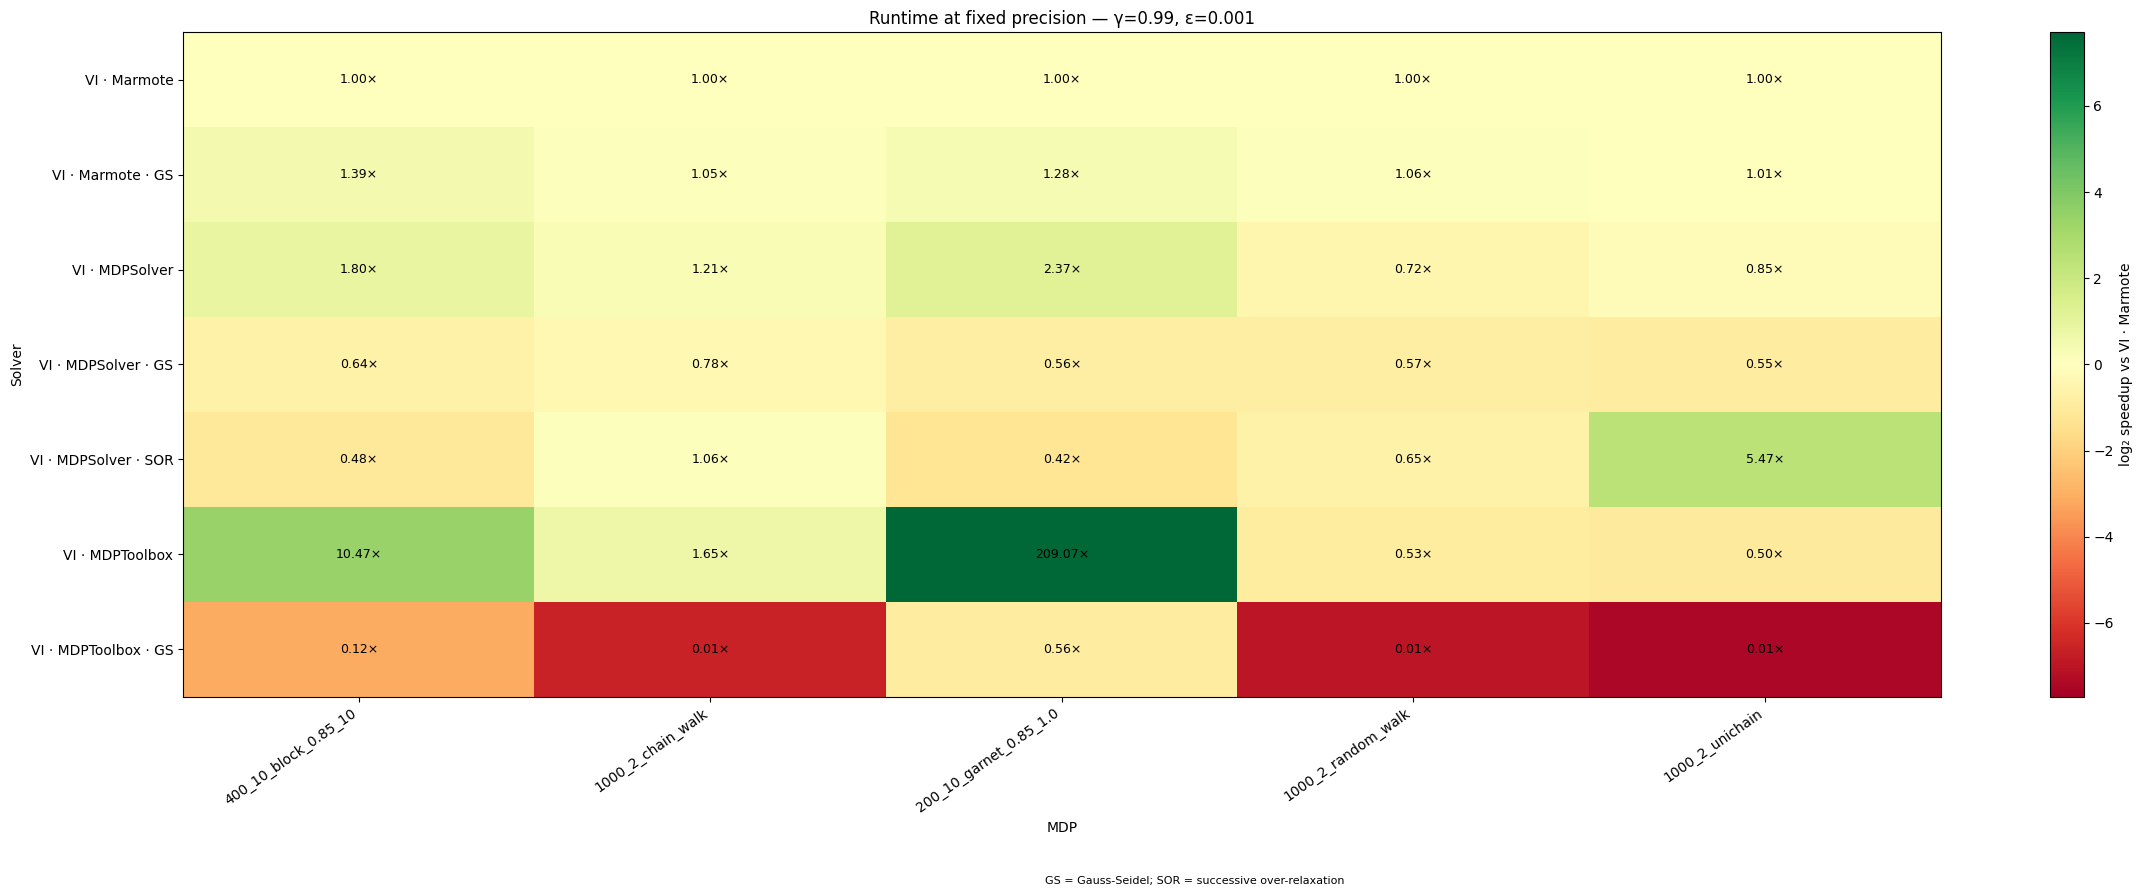

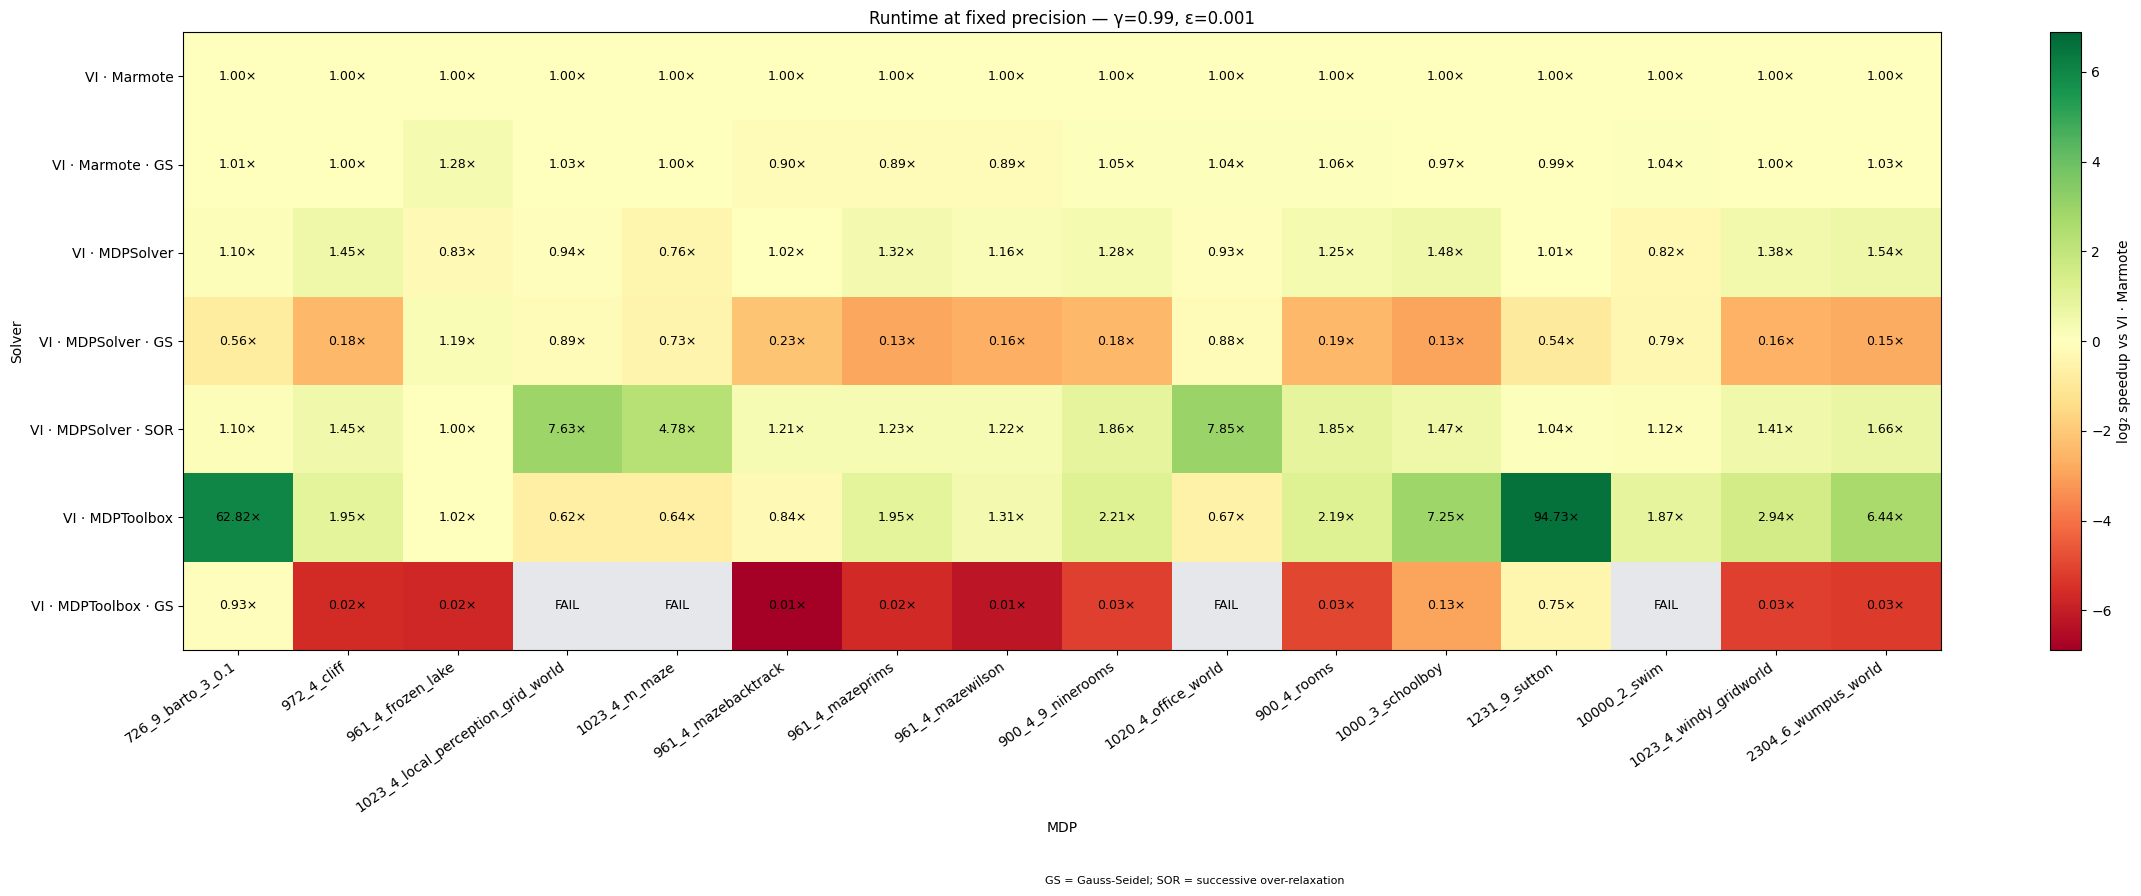

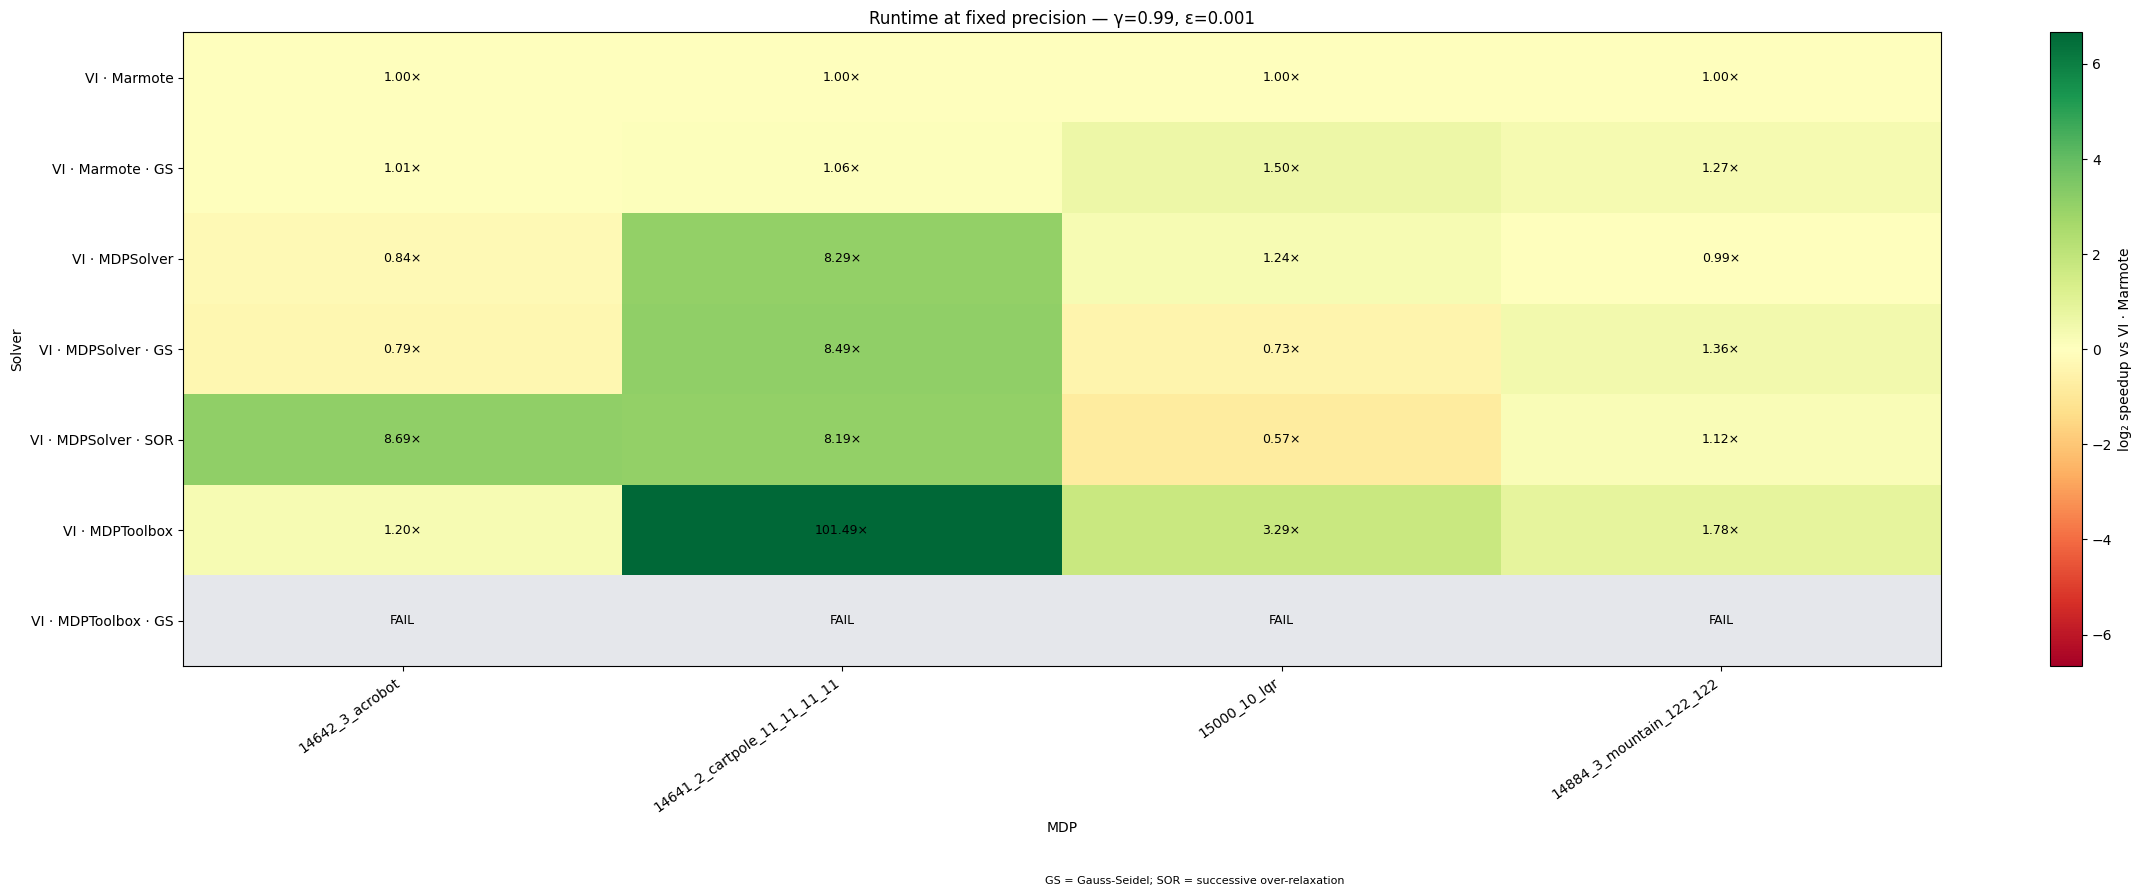

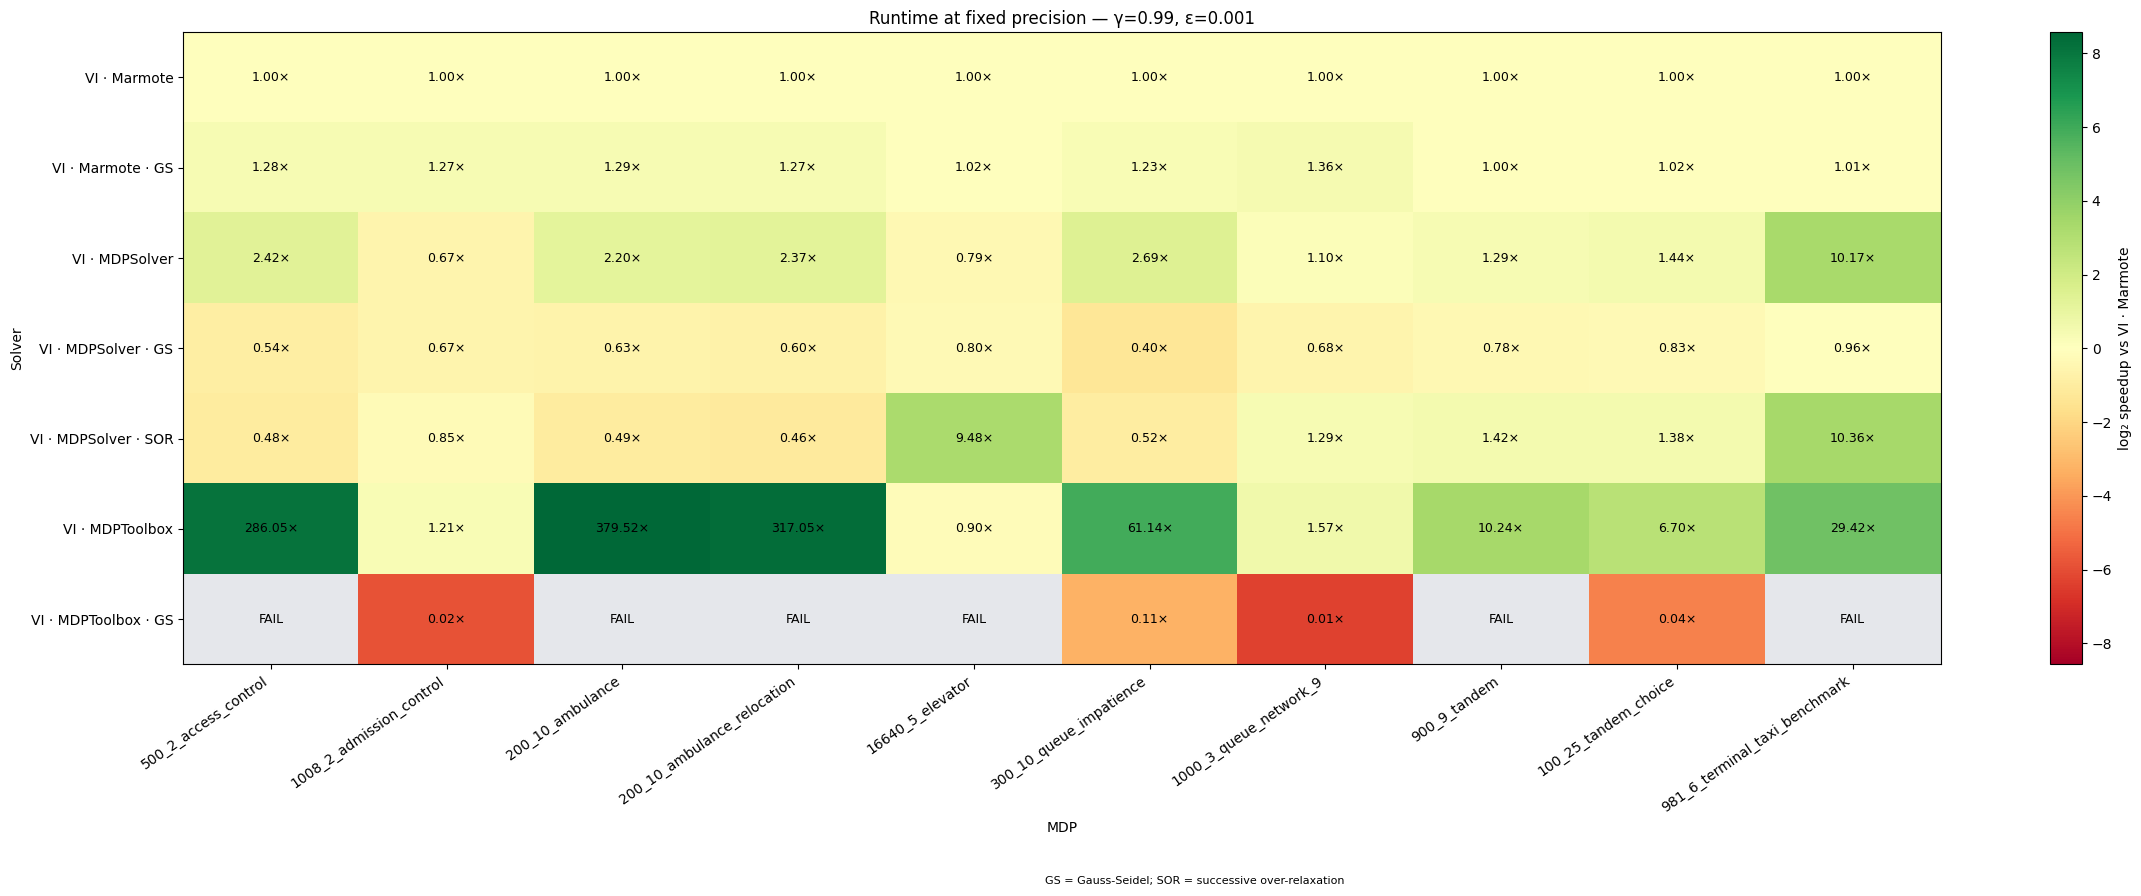

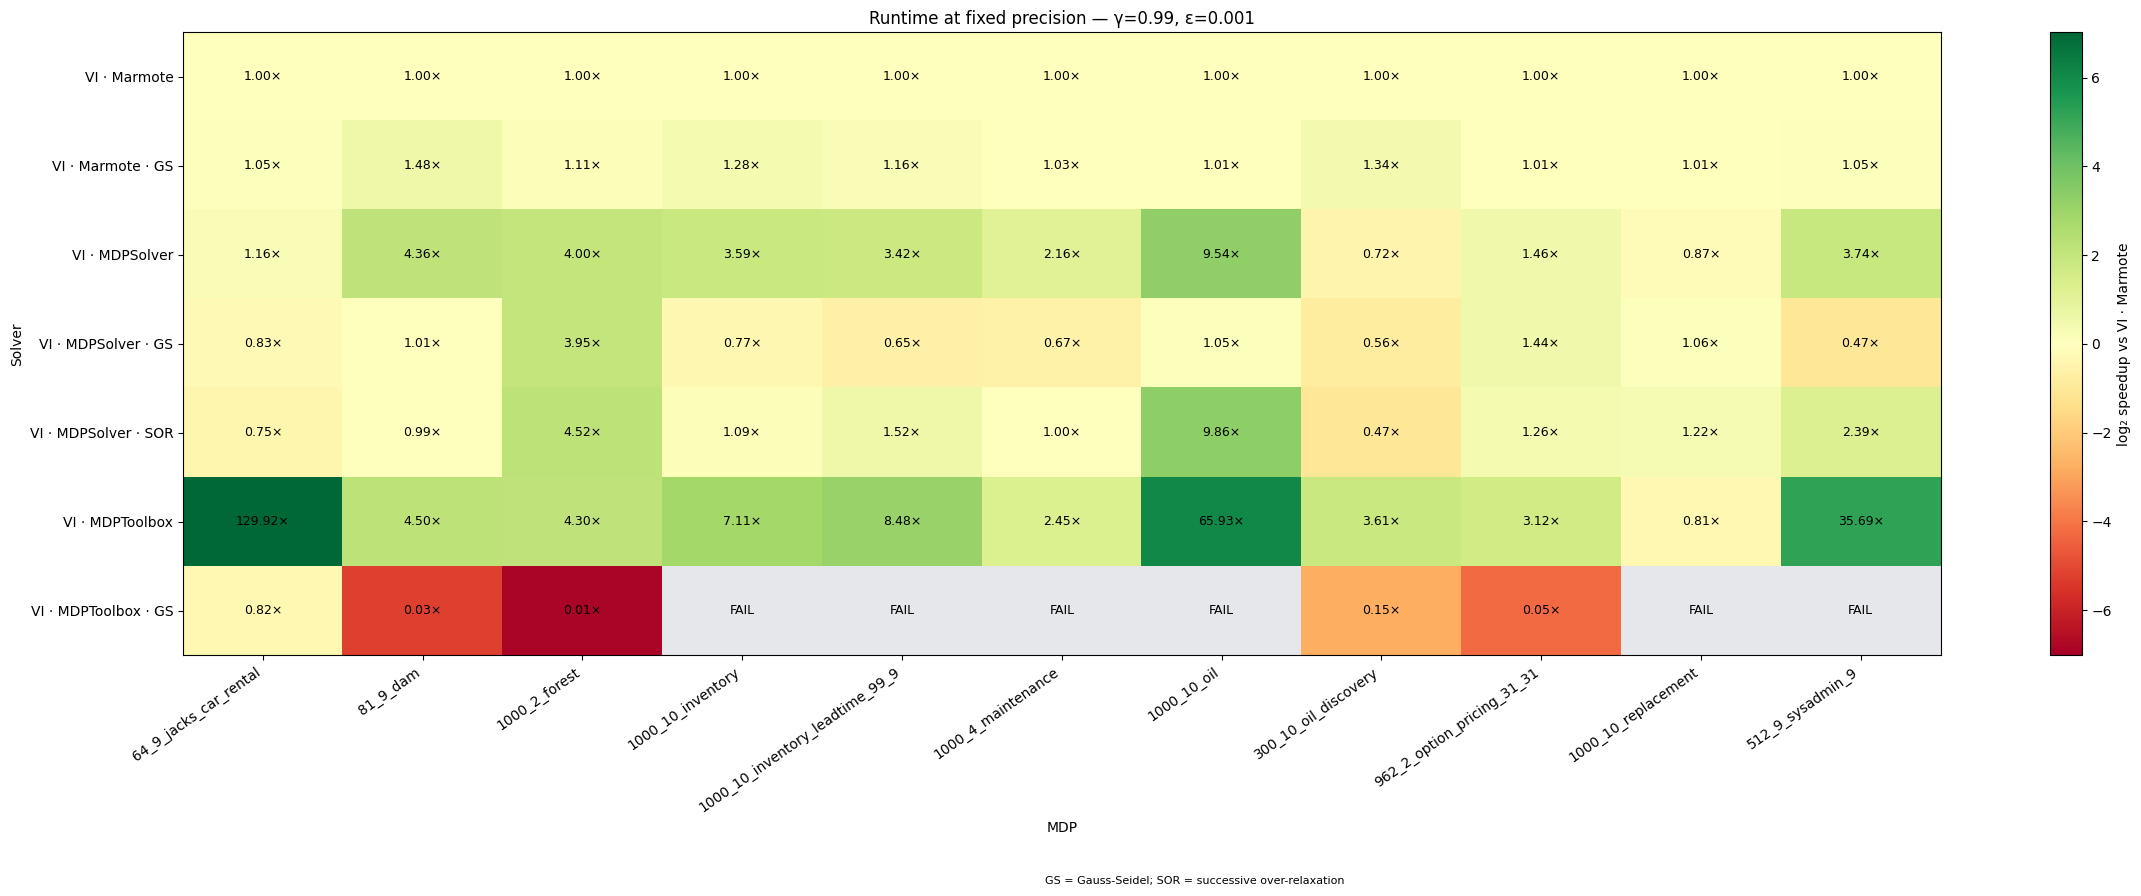

In [5]:
bench = Benchmark(default_solvers=False)

for cat in [
    "abstract",
    "navigation",
    "physical_control",
    "service_operations",
    "asset_management",
    "games_and_puzzles",
]:
    bench.reset()
    bench.add_solver(family=["vi"], backend=["mdpsolver", "marmote", "mdptoolbox"])
    bench.add_mdp(category=cat, size="medium")
    results = bench.run(
        discount=DISCOUNT,
        precision=PRECISION,
        repeats=REPEATS,
        seed=SEED,
        timeout=TIMEOUT,
    )

    fig, ax = plt.subplots(figsize=(24, 9))
    bench.plot_heat(reference="marmote_vi", ax=ax, show=False)
    plt.show()

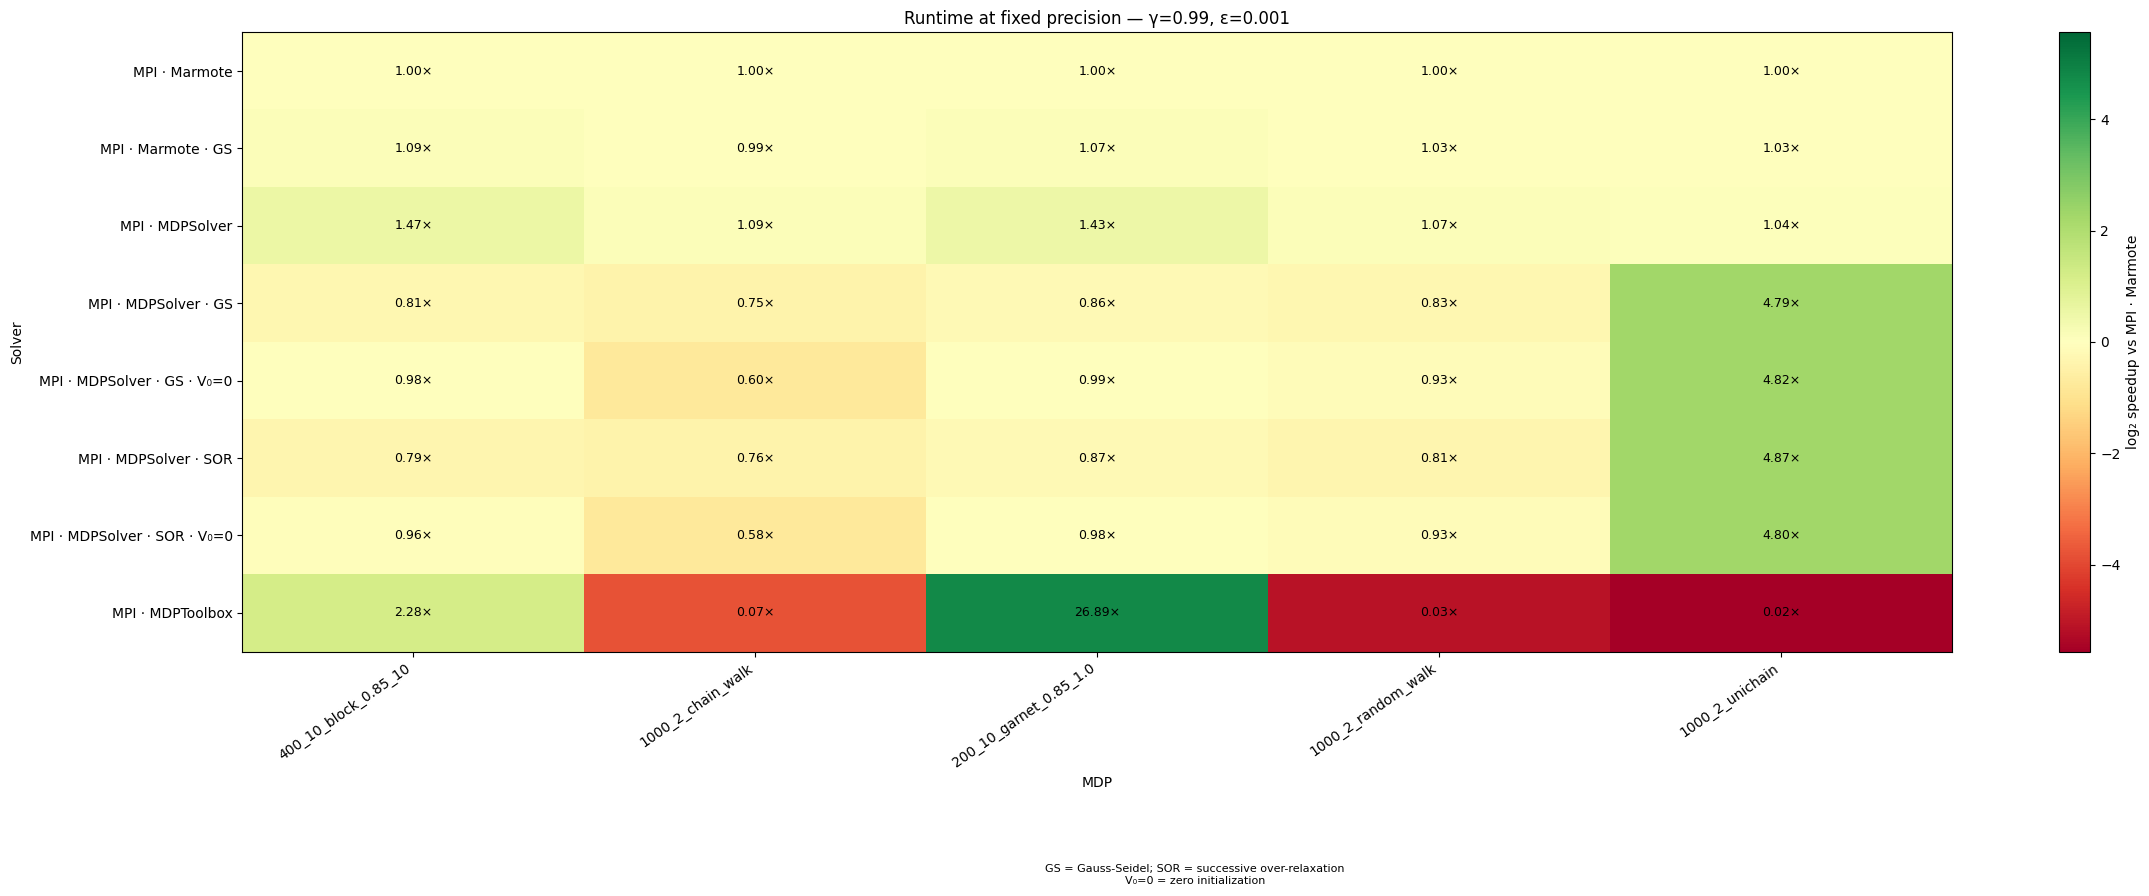

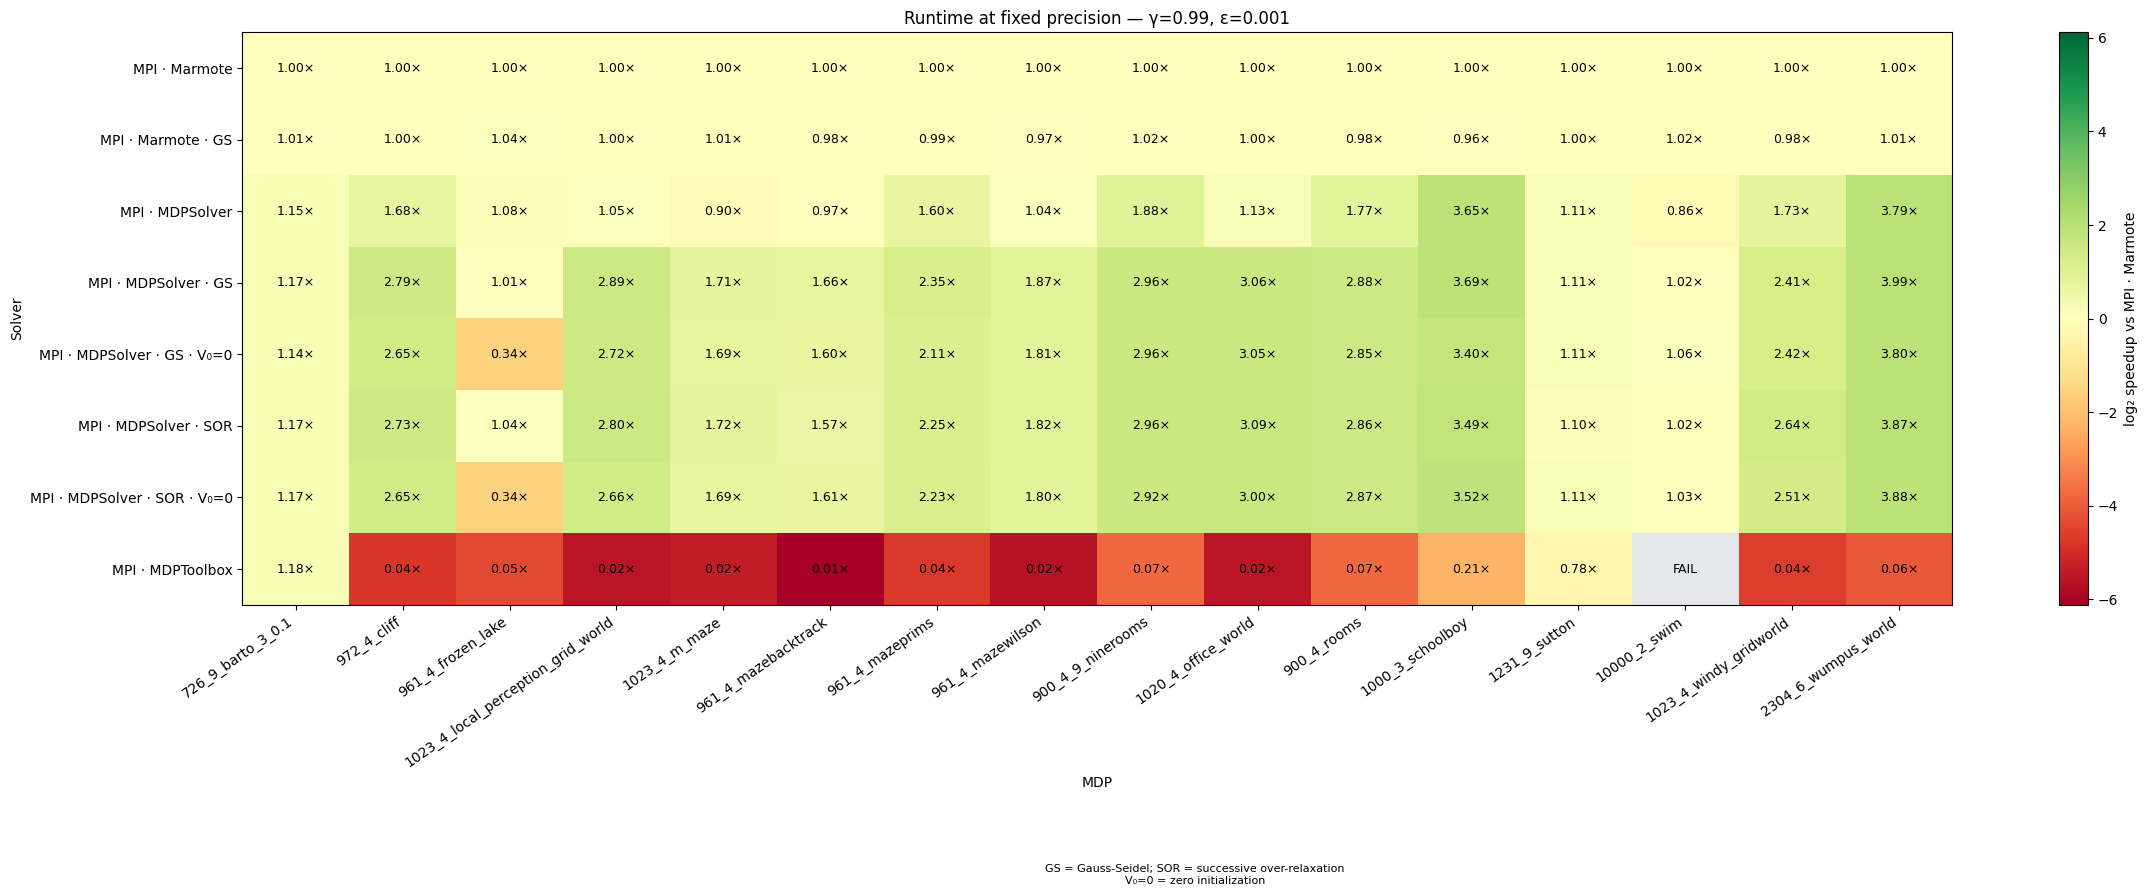

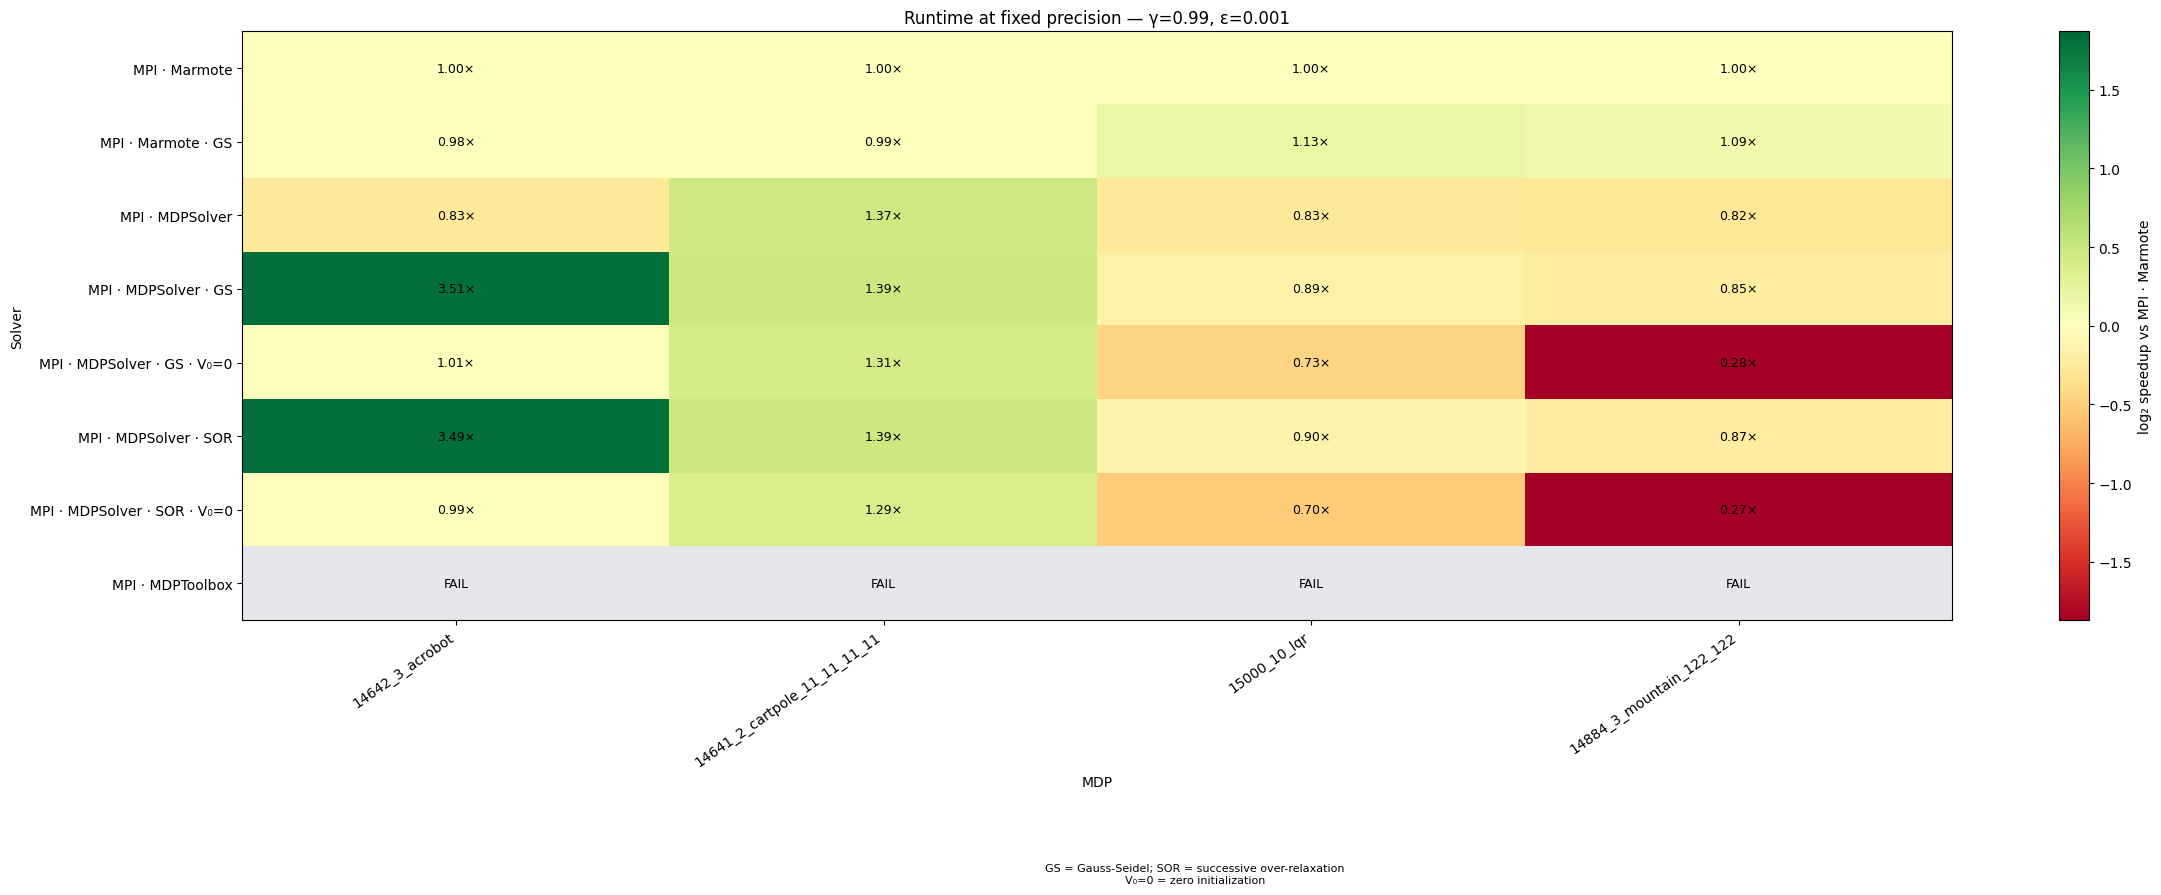

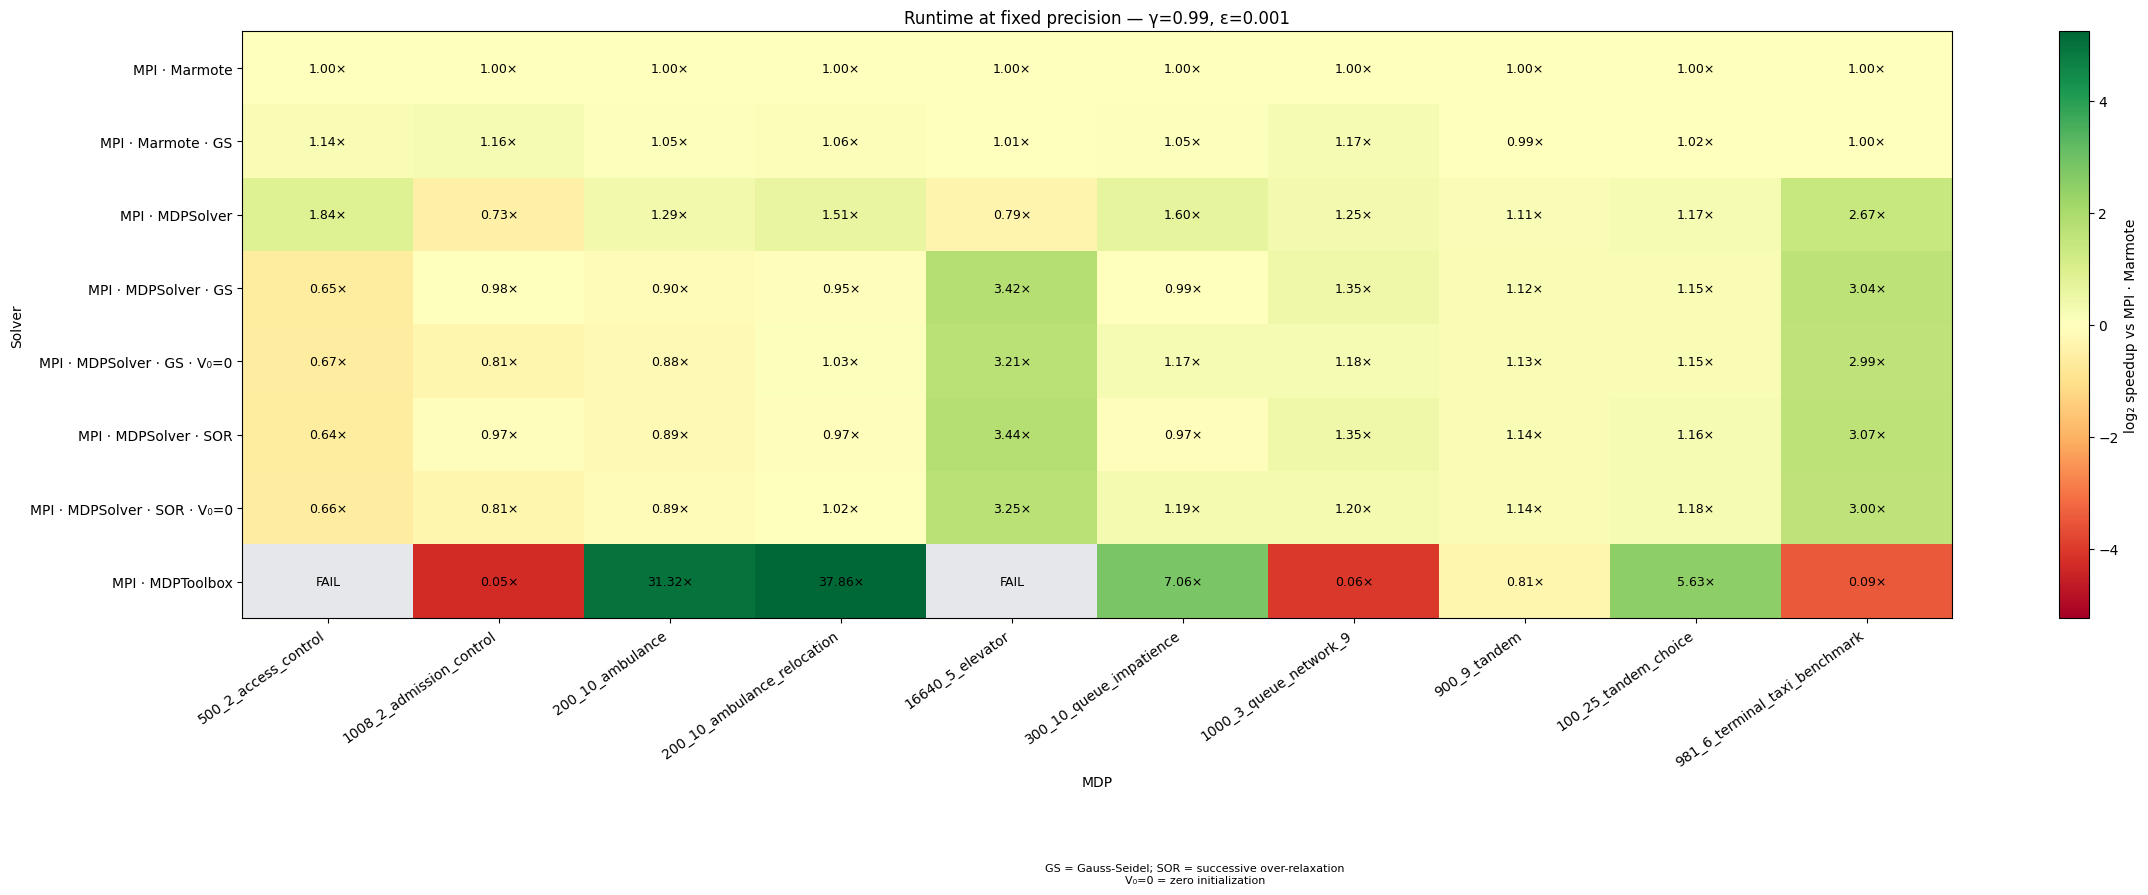

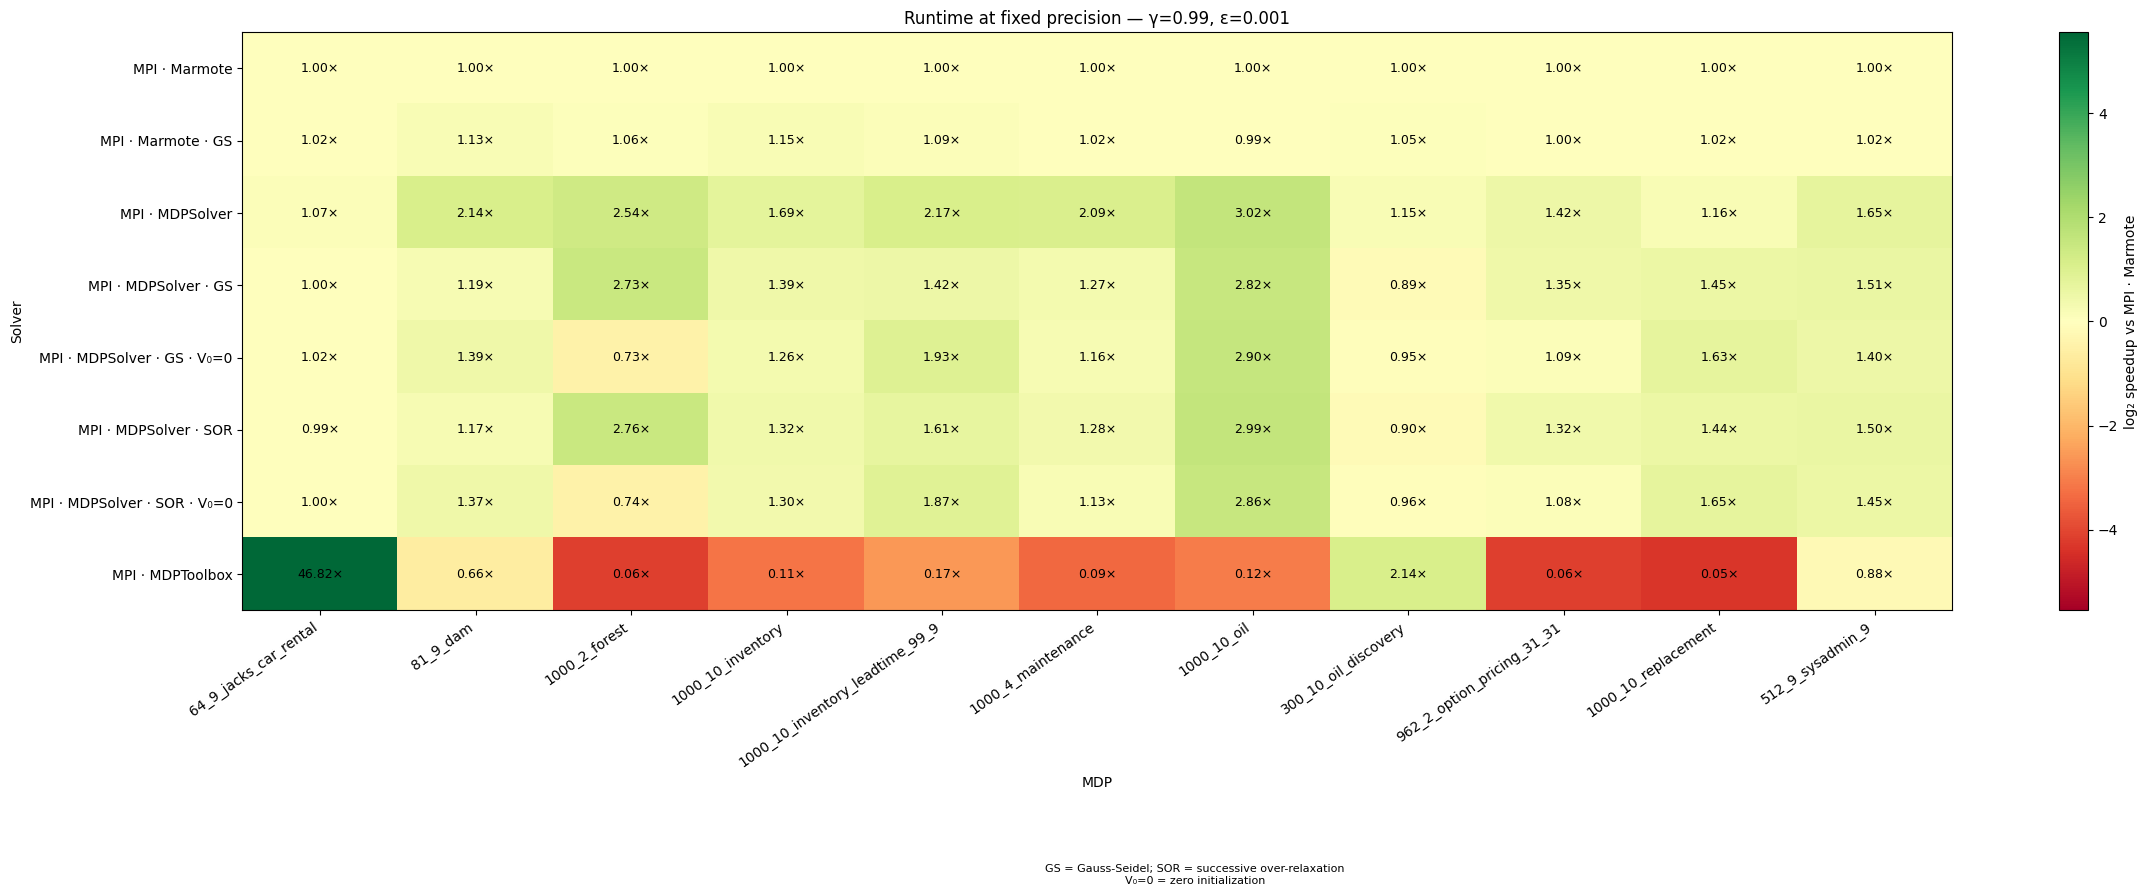

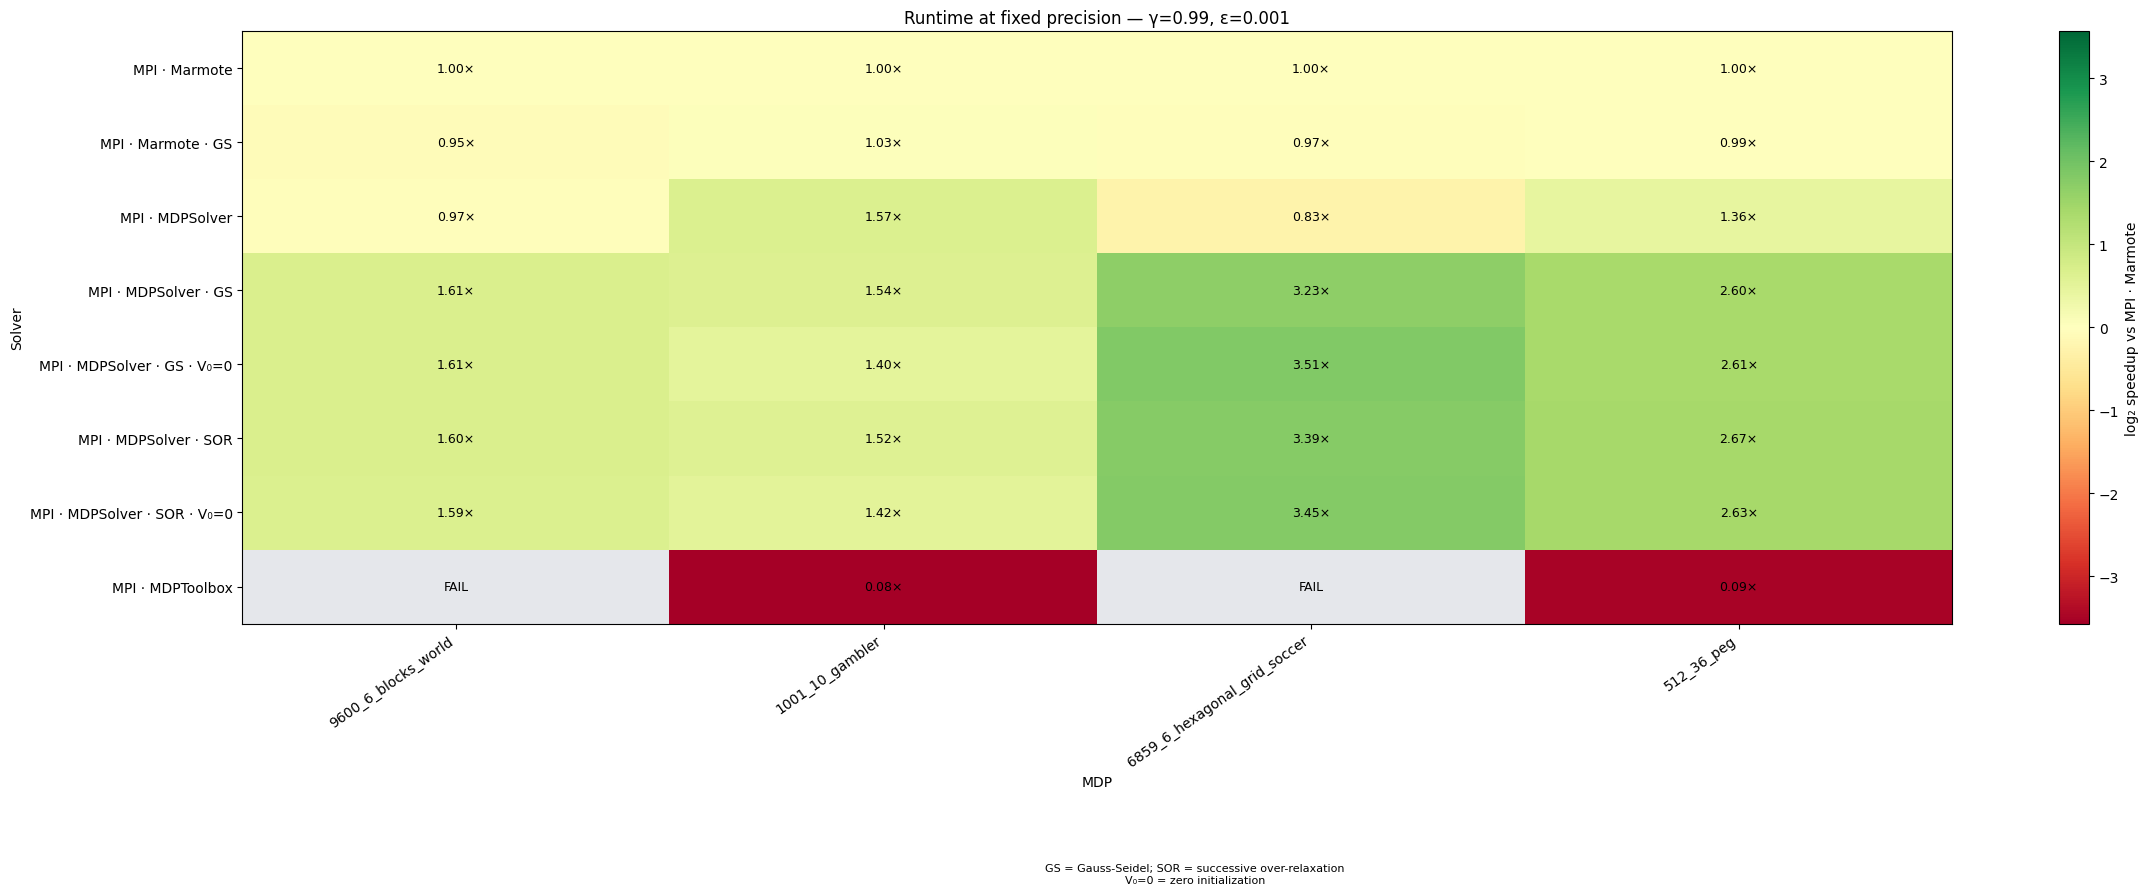

In [3]:
bench = Benchmark(default_solvers=False)

for cat in [
    "abstract",
    "navigation",
    "physical_control",
    "service_operations",
    "asset_management",
    "games_and_puzzles",
]:
    bench.reset()
    bench.add_solver(family=["mpi"], backend=["mdpsolver", "marmote", "mdptoolbox"])
    bench.add_mdp(category=cat, size="medium")
    results = bench.run(
        discount=DISCOUNT,
        precision=PRECISION,
        repeats=REPEATS,
        seed=SEED,
        timeout=TIMEOUT,
    )

    fig, ax = plt.subplots(figsize=(24, 9))
    bench.plot_heat(reference="marmote_mpi", ax=ax, show=False)
    plt.show()